In [1]:
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
import scipy as sp 
import scipy.stats as sps
import astropy
from astropy.io import fits
from scipy.stats import poisson
import statsmodels as sm
from scipy.special import gammaln
from matplotlib.ticker import MultipleLocator, AutoMinorLocator

In [2]:
t_0 = 52953 # MJD, arbitrary first time of observations
phi_init = (61192.9 - t_0)/316.65
phi = phi_init - int(phi_init)

print(phi_init, phi)

def phi_park(t, P): 
    t_0 = 54857 # reference point they're using in Park et al. 2025
    phi_init = (t - t_0)/P 
    phi = phi_init - int(phi_init)
    return phi

26.02210642665404 0.022106426654040945


In [20]:
# create october
october = np.arange(61314, 61345, 1)
# get phi_october
phi_october = []
for MJD in october: 
    phi_i = phi_park(MJD, 316.65)
    phi_october.append(phi_i)
october_dates = october - october[0] + 1

# actual observing dates
MJDs_observations_LaPalma = [
    61319.15685185, # 06/10/26
    61320.15837963, # 07/10/26
    61323.13725694, # 10/10/26
    61325.13973380, # 12/10/26
    61326.13486111, # 13/10/26
    61327.24471065, # 14/10/26
    61328.15228009, # 15/10/26
]
lapalma_phis = []
for MJD in MJDs_observations_LaPalma: 
    phi_i = phi_park(MJD, 316.65)
    lapalma_phis.append(phi_i)

In [21]:
phi_october[5], phi_october[14]

(np.float64(0.40738986262434906), np.float64(0.43581241117953695))

In [22]:
lapalma_phis[0], lapalma_phis[-1]

(0.40788521032685665, 0.4362933209853104)

In [7]:
len(phi_october)

31

In [8]:
park_salt = np.loadtxt('Park_SALT_data.csv', delimiter=',')
phis_park = park_salt[:,0]
EWs_park = park_salt[:,1]
MJDs_minus_60000 = np.arange(263.1914893617021, 450, 3)
MJDs_park_SALT = MJDs_minus_60000 + 60000


In [9]:
MJDs_points_SALT = np.loadtxt('data (3).csv', delimiter=',')
MJDs_SALT = MJDs_points_SALT[:,0]
EWs_park_MJDs = MJDs_points_SALT[:,1]

In [10]:
MJDs_SALT

array([262.55907278, 274.53709758, 282.4726592 , 302.36124466,
       326.43973486, 357.57875303, 361.55903432, 362.65651243,
       365.63547316, 367.61503648, 366.65987153, 368.72213034,
       372.5184302 ])

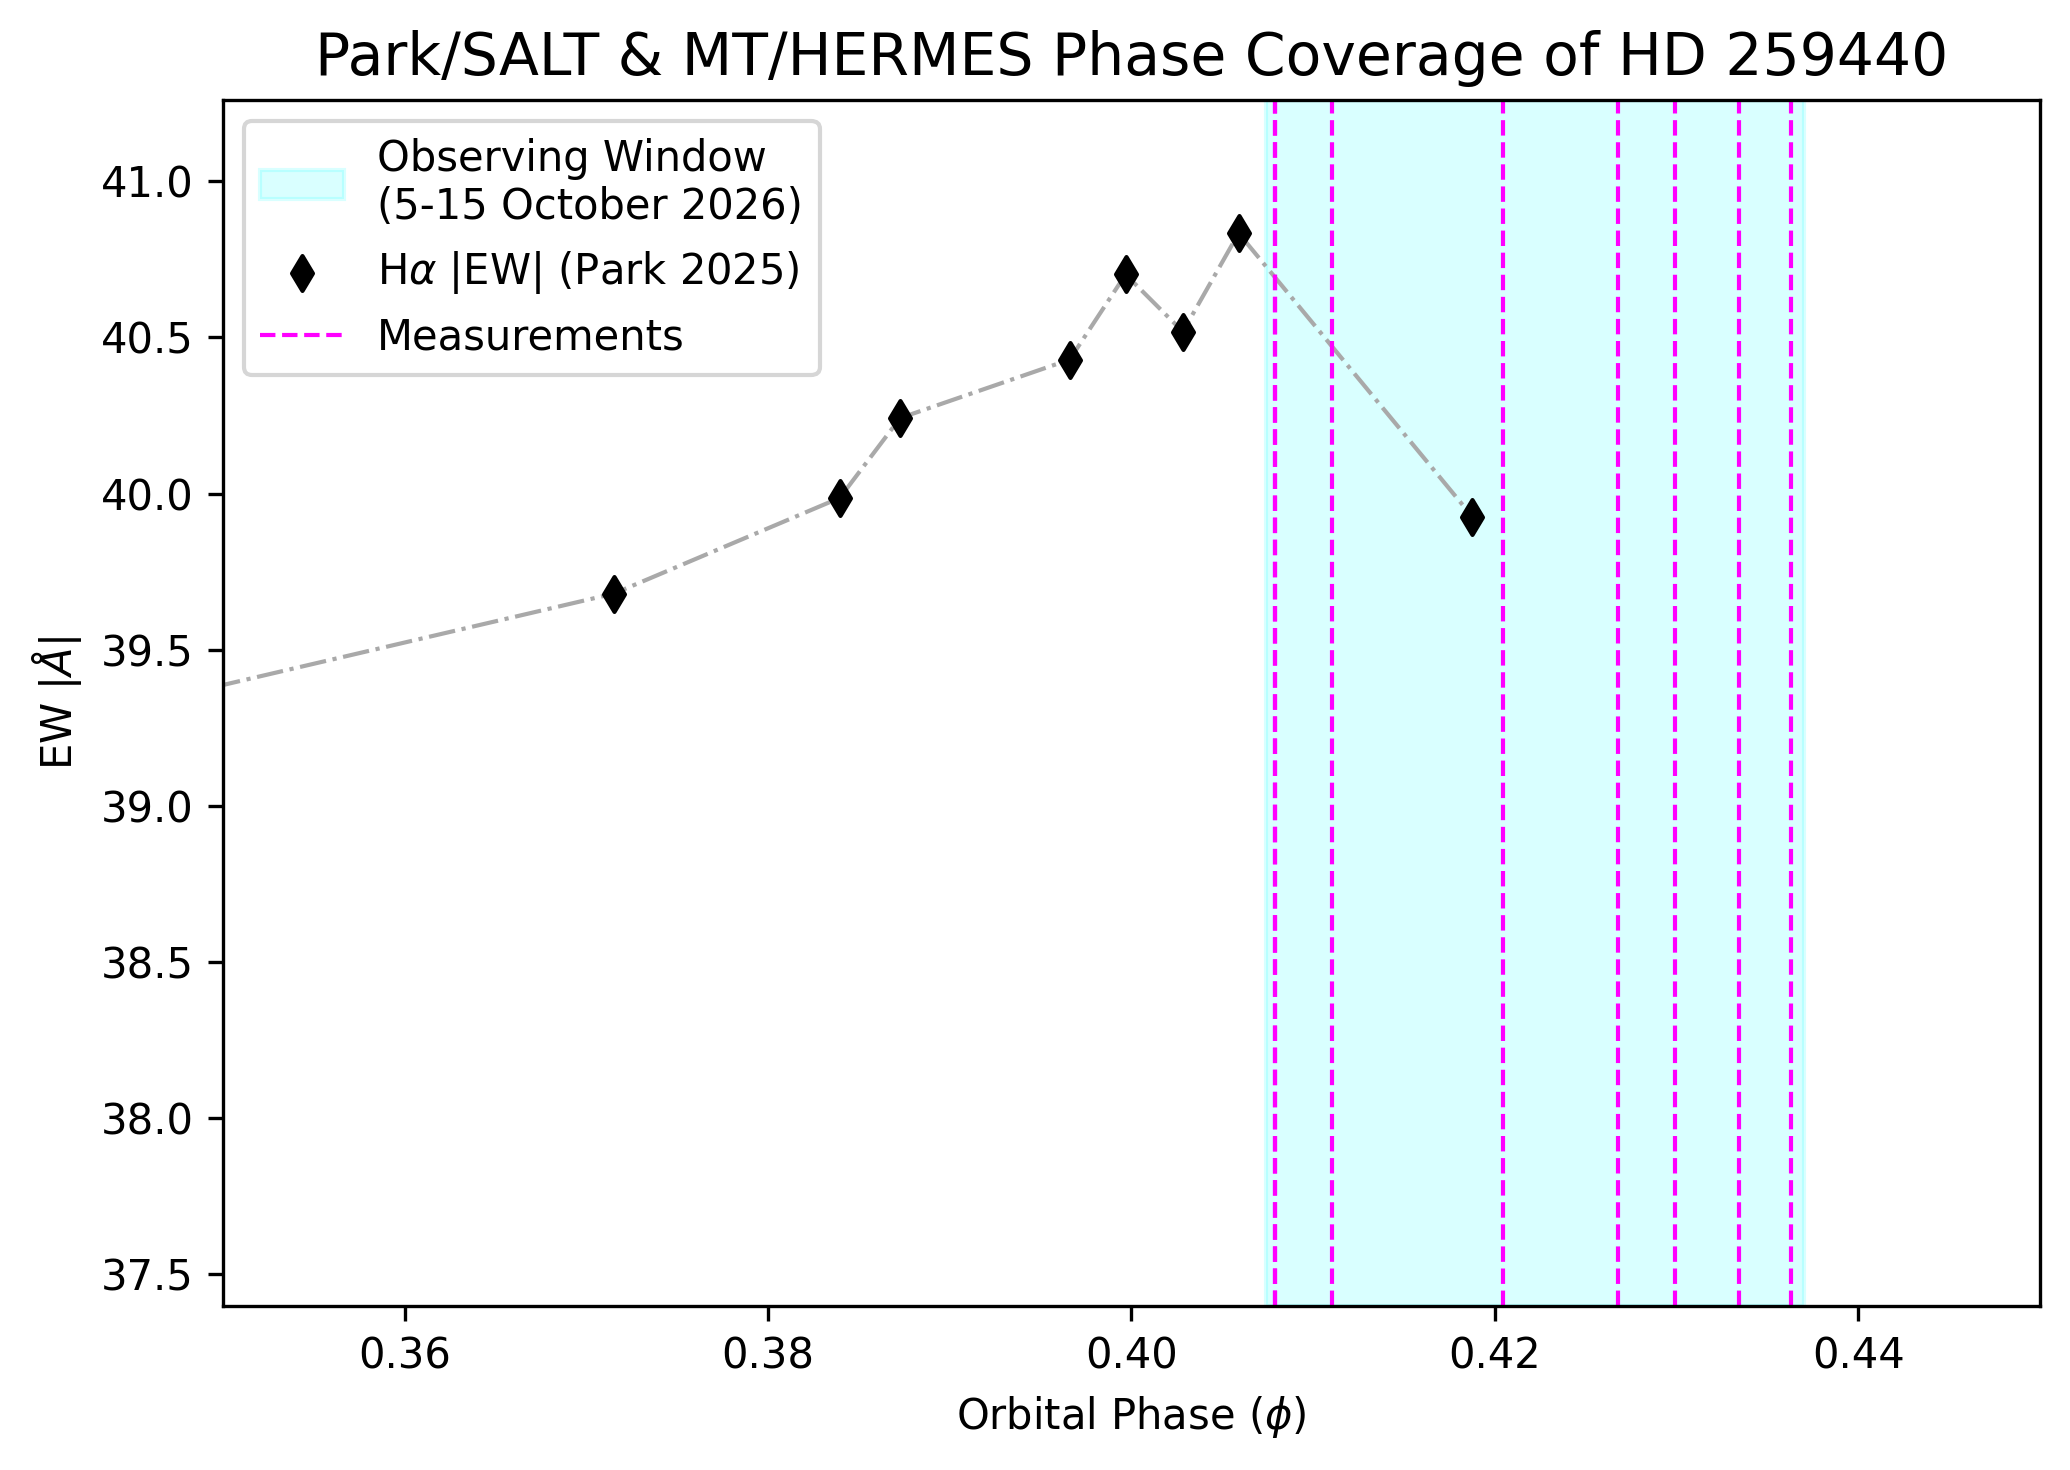

In [36]:
fig, ax = plt.subplots(dpi=300, figsize=(7,5))
# Create the primary plot
ax.axvspan(phi_october[5], 0.437, color='cyan', alpha=0.15, label='Observing Window\n(5-15 October 2026)')
ax.plot(phis_park, EWs_park, zorder = 1, ls = 'dashdot', color='darkgrey', lw=1)
ax.scatter(phis_park, EWs_park,lw=1, s=35, marker='d', zorder=2, label=f'H$\\alpha$ $|\\rm EW|$ (Park 2025)', color='black') #facecolors='none', edgecolor='black', 
for date in lapalma_phis: 
    ax.axvline(date, lw=1, ls='dashed', color='magenta')
ax.axvline(lapalma_phis[0], lw=1, ls='dashed', color='magenta', label='Measurements')

ax.set_xlabel('Orbital Phase ($\phi$)')
ax.set_ylabel('EW $|\AA|$')
ax.set_ylim(min(EWs_park) - 0.3, 41.26)
ax.set_xlim(0.35, 0.45)

ax.legend(fontsize=10)
plt.title('Park/SALT & MT/HERMES Phase Coverage of HD 259440', fontsize=14)
plt.tight_layout()
plt.show()

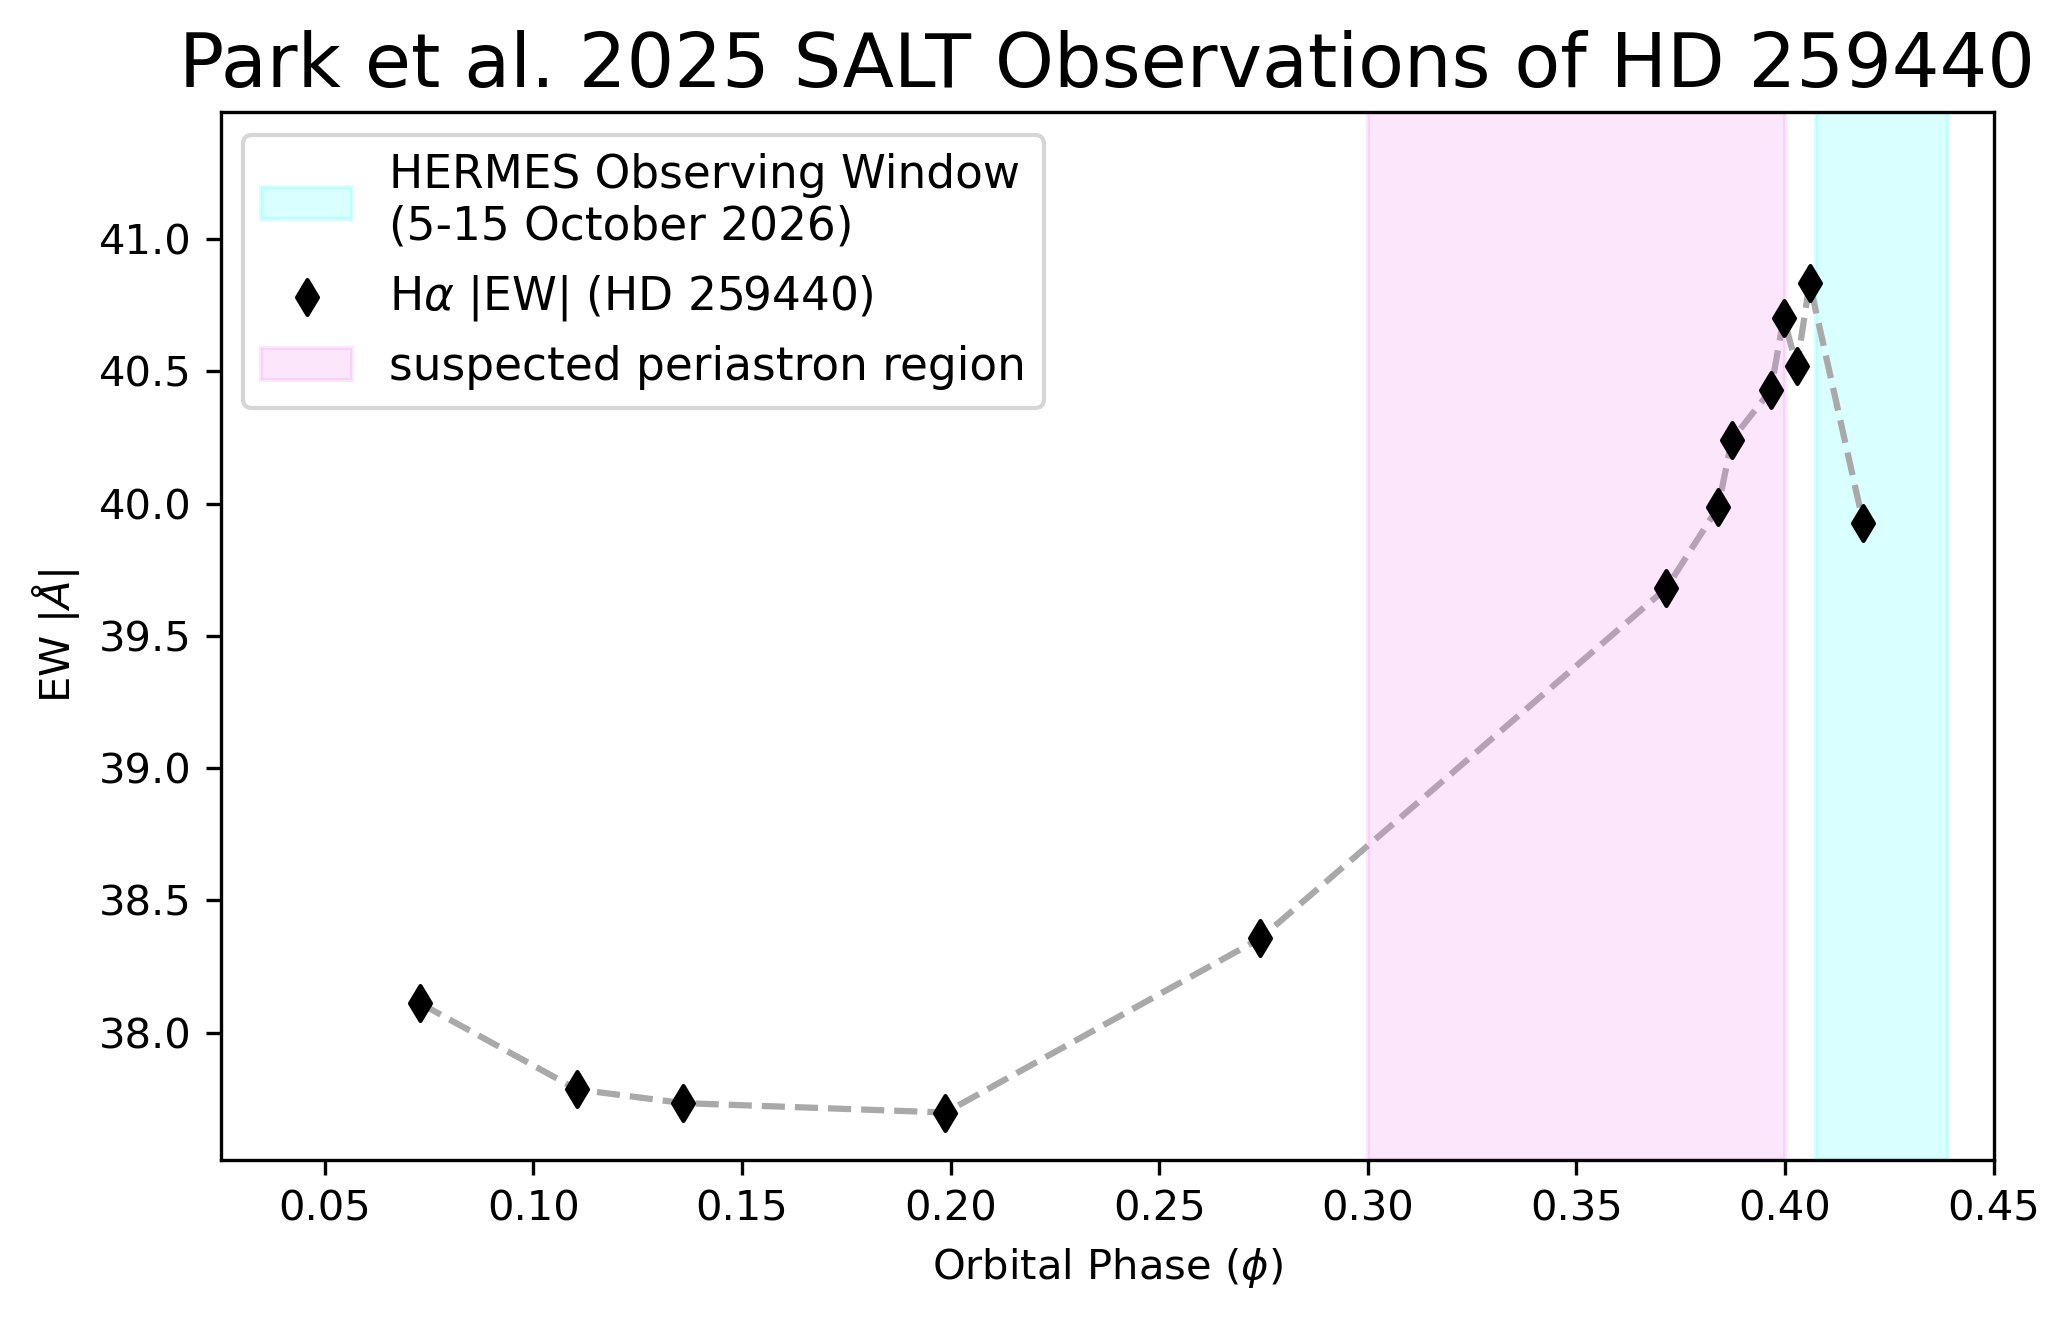

In [57]:
fig, ax = plt.subplots(dpi=300, figsize=(7,4.5))
# Create the primary plot
ax.axvspan(phi_october[5], phi_october[15], color='cyan', alpha=0.15, label='HERMES Observing Window\n(5-15 October 2026)')
ax.plot(phis_park, EWs_park, zorder = 1, ls = 'dashed', color='darkgrey', lw=1.5)
ax.scatter(phi_park_400, 41.3, lw=0.1)
ax.scatter(phis_park, EWs_park,lw=1, s=35, marker='d', zorder=2, label=f'H$\\alpha$ $|\\rm EW|$ (HD 259440)', color='black') #facecolors='none', edgecolor='black', 

# ax.axvline(phi_october[5], ls = 'dotted', color='dodgerblue')
# ax.axvline(phi_october[7], ls = 'dotted', color='dodgerblue')
# ax.axvline(phi_october[9], ls = 'dotted', color='dodgerblue')
# ax.axvline(phi_october[11], ls = 'dotted', color='dodgerblue')
# ax.axvline(phi_october[13], ls = 'dotted', color='dodgerblue', label = 'Observing Epochs')
ax.axvspan(0.3, 0.4, alpha = 0.2, color = 'violet', label = 'suspected periastron region')

ax.set_xlabel('Orbital Phase ($\phi$)')
ax.set_ylabel('EW $|\AA|$')
# Add the secondary x-axis at the top

#ax.set_ylim(39)
#ax.set_xlim(min(phis_park) - 0.03, 0.48)
#ax.set_ylim(38, 41.26)
ax.set_xlim(0.025, 0.45)
ax.legend(fontsize=10.9)
plt.title('Park et al. 2025 SALT Observations of HD 259440', fontsize=18)
plt.tight_layout()
plt.show()

In [43]:
len(high_cad_phase)

0

In [44]:
phis_park

array([0.07289941, 0.11039995, 0.13585405, 0.19875413, 0.274266  ,
       0.37151656, 0.38395036, 0.38727022, 0.39660239, 0.39967947,
       0.40282952, 0.40589978, 0.418768  ])

In [45]:
high_cad_phase = phis_park[phis_park>0.35]
high_cad_EWs = EWs_park[EWs_park>39]

mean_EWs = np.mean(high_cad_EWs) 

normed_highcad_EWs = high_cad_EWs/mean_EWs


(0.975, 1.03)

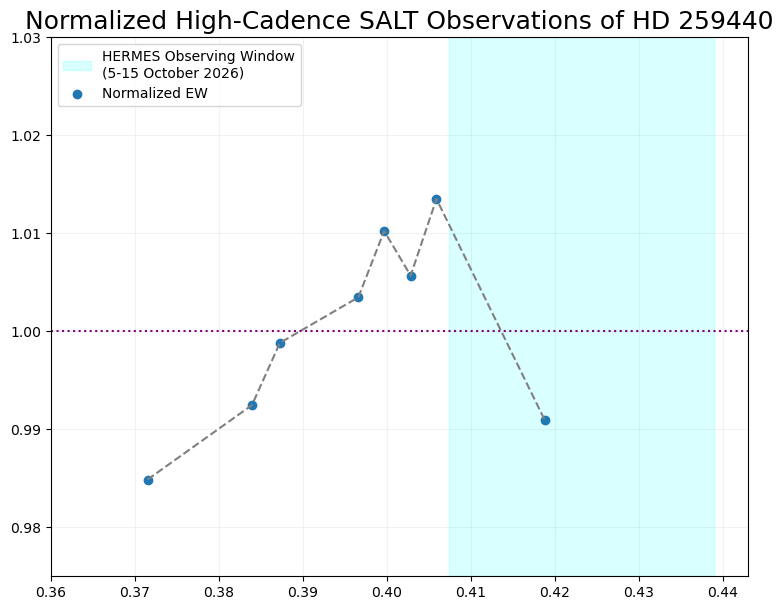

In [61]:
plt.figure(figsize=(9,7))
plt.plot(high_cad_phase, normed_highcad_EWs, ls = 'dashed', color='gray')
plt.axvspan(phi_october[5], phi_october[15], color='cyan', alpha=0.15, label='HERMES Observing Window\n(5-15 October 2026)')
plt.axhline(y = 1, ls = 'dotted', color='purple',lw=1.5)
plt.scatter(high_cad_phase, normed_highcad_EWs, label='Normalized EW')
plt.title('Normalized High-Cadence SALT Observations of HD 259440', fontsize=18)
plt.grid(True, color = 'gray', alpha=0.1)
plt.legend()
plt.xlim(0.36, 0.443)
plt.ylim(0.975, 1.03)

In [ ]:
fig, ax = plt.subplots(dpi=300, figsize=(7,4.5))
# Create the primary plot
ax.axvspan(phi_october[5], phi_october[15], color='cyan', alpha=0.15, label='HERMES Observing Window\n(5-15 October 2026)')
ax.plot(phis_park, EWs_park, zorder = 1, ls = 'dashed', color='darkgrey', lw=1.5)
ax.scatter(phi_park_400, 41.3, lw=0.1)
ax.scatter(phis_park, EWs_park,lw=1, s=35, marker='d', zorder=2, label=f'H$\\alpha$ $|\\rm EW|$ (HD 259440)', color='black') #facecolors='none', edgecolor='black', 

# ax.axvline(phi_october[5], ls = 'dotted', color='dodgerblue')
# ax.axvline(phi_october[7], ls = 'dotted', color='dodgerblue')
# ax.axvline(phi_october[9], ls = 'dotted', color='dodgerblue')
# ax.axvline(phi_october[11], ls = 'dotted', color='dodgerblue')
# ax.axvline(phi_october[13], ls = 'dotted', color='dodgerblue', label = 'Observing Epochs')
#ax.axvspan(0.315, 0.36, alpha = 0.4, color = 'pink', label = 'suspected periastron region')

ax.set_xlabel('Orbital Phase ($\phi$)')
ax.set_ylabel('EW $|\AA|$')
# Add the secondary x-axis at the top

#ax.set_ylim(39)
#ax.set_xlim(min(phis_park) - 0.03, 0.48)
#ax.set_ylim(38, 41.26)
ax.set_xlim(0.025, 0.45)
ax.legend(fontsize=10.9)
plt.title('Park et al. 2025 SALT Observations of HD 259440', fontsize=18)
plt.tight_layout()
plt.show()

MEASURING PEAK INCREASE PARAMETERS FOR PAPER

In [160]:
EWs_park[-8:]

array([39.67942223, 39.98593764, 40.24153862, 40.42881137, 40.70146372,
       40.51814837, 40.83341452, 39.92543072])

In [162]:
39.67942223 - 40.83341452 # this is the delta in EW 

-1.153992289999998

In [165]:
MJDs_SALT[-8:]

array([357.57875303, 361.55903432, 362.65651243, 365.63547316,
       367.61503648, 366.65987153, 368.72213034, 372.5184302 ])

In [75]:
MJDs_SALT[-1]

372.5184301960332

In [102]:
EWs_park

array([38.10998921, 37.78521241, 37.73345622, 37.69783365, 38.35650625,
       39.67942223, 39.98593764, 40.24153862, 40.42881137, 40.70146372,
       40.51814837, 40.83341452, 39.92543072])

In [79]:
EWs_park[-2] - EWs_park[-1]

0.9079838040271682

In [77]:
MJDs_SALT[-2] - MJDs_SALT[-1]

-3.796299857686847

In [166]:
357.57875303 - 366.65987153

-9.081118500000002

In [19]:
phi_october

[0.3915995578714693,
 0.3947576188220445,
 0.39791567977261977,
 0.40107374072319857,
 0.4042318016737738,
 0.40738986262434906,
 0.41054792357492786,
 0.4137059845255031,
 0.41686404547607836,
 0.42002210642665716,
 0.4231801673772324,
 0.42633822832780766,
 0.4294962892783829,
 0.4326543502289617,
 0.43581241117953695,
 0.4389704721301122,
 0.442128533080691,
 0.44528659403126625,
 0.4484446549818415,
 0.4516027159324203,
 0.45476077688299554,
 0.4579188378335708,
 0.4610768987841496,
 0.46423495973472484,
 0.4673930206853001,
 0.47055108163587533,
 0.47370914258645413,
 0.4768672035370294,
 0.48002526448760463,
 0.48318332543818343,
 0.4863413863887587]

In [20]:
263.1914893617021, 41.19602272727273
270.0303951367781, 41.19602272727273
300.04559270516717, 41.19602272727273
339.9392097264438, 41.19602272727273
360, 41.19602272727273
374.9696048632219, 41.19602272727273

(374.9696048632219, 41.19602272727273)